In [2]:
import xarray as xr
import numpy as np

spei_path = r"C:\Users\franc\spei1_spei3_1981_2025.nc"

ds = xr.open_dataset(
    spei_path,
    decode_timedelta=False
)

print("Dimensions:")
for dim, size in ds.sizes.items():
    print(f"  {dim}: {size}")

print("\nCoordinates:")
for coord in ds.coords:
    print(f"  {coord}: {ds[coord].dims}")

print("\nData variables:")
for var in ds.data_vars:
    print(f"  {var}")
    print(f"    dims: {ds[var].dims}")
    print(f"    shape: {ds[var].shape}")
    print(f"    attrs: {dict(ds[var].attrs)}")

print("\nTime range:")
if "time" in ds.coords:
    print("  Start:", ds["time"].values[0])
    print("  End:  ", ds["time"].values[-1])

Dimensions:
  time: 16436
  lat: 141
  lon: 220

Coordinates:
  time: ('time',)
  lat: ('lat',)
  lon: ('lon',)
  dayofyear: ('time',)

Data variables:
  spei1
    dims: ('time', 'lat', 'lon')
    shape: (16436, 141, 220)
    attrs: {'long_name': 'Standardized 30-day climatic water balance index', 'description': 'SPEI-like index based on day-of-year standardization of 30-day accumulated P-Ep'}
  spei3
    dims: ('time', 'lat', 'lon')
    shape: (16436, 141, 220)
    attrs: {'long_name': 'Standardized 90-day climatic water balance index', 'description': 'SPEI-like index based on day-of-year standardization of 90-day accumulated P-Ep'}

Time range:
  Start: 1981-01-01T00:00:00.000000000
  End:   2025-12-31T00:00:00.000000000


In [3]:
import geopandas as gpd
from shapely.geometry import Point
import numpy as np

# ============================================================
# PROVINCE SHAPEFILE / GEOPACKAGE
# ============================================================

province_path = r"C:\Users\franc\South_Africa_Provinces\South_Africa_Provinces.gpkg"

study_provinces = [
    "Free State",
    "North West",
    "Gauteng",
    "Mpumalanga",
    "KwaZulu-Natal"
]

# Read province boundaries
provinces = gpd.read_file(province_path)

# Keep only the five study provinces
study_gdf = provinces[
    provinces["ProvinceName"].isin(study_provinces)
].copy()

# Make sure coordinates match SPEI lat/lon coordinates
study_gdf = study_gdf.to_crs("EPSG:4326")

print("Selected provinces:")
print(study_gdf["ProvinceName"].tolist())

# ============================================================
# CREATE STUDY-REGION MASK ON SPEI GRID
# ============================================================

try:
    study_geometry = study_gdf.geometry.union_all()
except AttributeError:
    study_geometry = study_gdf.geometry.unary_union

lat = ds["lat"].values
lon = ds["lon"].values

mask = np.zeros((len(lat), len(lon)), dtype=bool)

for i, y in enumerate(lat):
    for j, x in enumerate(lon):
        mask[i, j] = study_geometry.covers(Point(x, y))

study_mask = xr.DataArray(
    mask,
    coords={
        "lat": ds["lat"],
        "lon": ds["lon"]
    },
    dims=("lat", "lon")
)

print("\nSPEI grid cells:", mask.size)
print("Cells inside five study provinces:", int(mask.sum()))
print("Cells outside study provinces:", int((~mask).sum()))

Selected provinces:
['Mpumalanga', 'North West', 'Gauteng', 'Free State', 'KwaZulu-Natal']

SPEI grid cells: 31020
Cells inside five study provinces: 3865
Cells outside study provinces: 27155


In [4]:
# ============================================================
# MASK SPEI-3 TO THE FIVE STUDY PROVINCES
# ============================================================

spei3_study = ds["spei3"].where(study_mask)

# Spatial mean across all grid cells in the study region
spei3_region_mean = spei3_study.mean(
    dim=["lat", "lon"],
    skipna=True
)

print("Regional SPEI-3 time series")
print("---------------------------")
print("Number of time steps:", spei3_region_mean.sizes["time"])
print("Start:", spei3_region_mean["time"].values[0])
print("End:  ", spei3_region_mean["time"].values[-1])

print("\nSummary:")
print("Minimum:", float(spei3_region_mean.min()))
print("Mean:   ", float(spei3_region_mean.mean()))
print("Maximum:", float(spei3_region_mean.max()))

Regional SPEI-3 time series
---------------------------
Number of time steps: 16436
Start: 1981-01-01T00:00:00.000000000
End:   2025-12-31T00:00:00.000000000

Summary:
Minimum: -2.3514604568481445
Mean:    3.566579778180312e-07
Maximum: 3.4011123180389404


In [5]:
# ============================================================
# REGIONAL SPEI-3 ANOMALIES
# ============================================================

spei3_climatological_mean = spei3_region_mean.mean(
    dim="time",
    skipna=True
)

spei3_anomaly = spei3_region_mean - spei3_climatological_mean

print("Regional SPEI-3 climatological mean:")
print(float(spei3_climatological_mean))

print("\nAnomaly summary:")
print("Minimum:", float(spei3_anomaly.min()))
print("Mean:   ", float(spei3_anomaly.mean()))
print("Maximum:", float(spei3_anomaly.max()))

Regional SPEI-3 climatological mean:
3.566579778180312e-07

Anomaly summary:
Minimum: -2.3514608135061223
Mean:    -3.5645790057348123e-07
Maximum: 3.4011119613809626


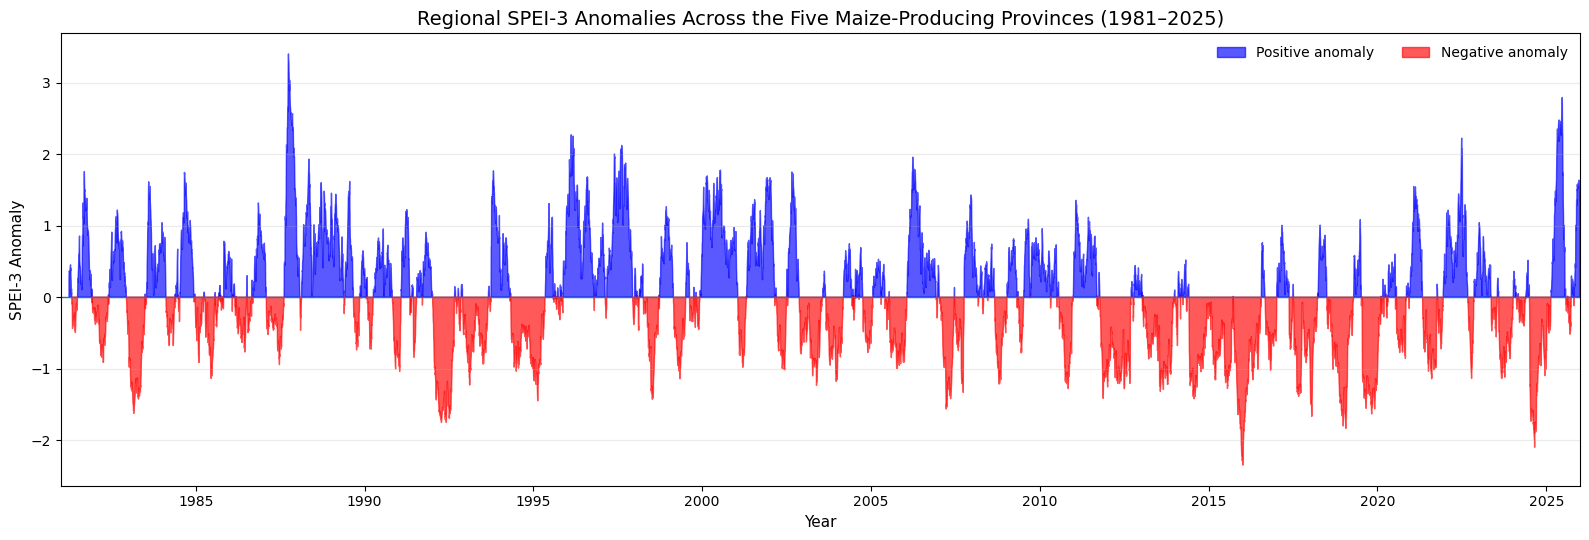

Saved:
C:\Users\franc\regional_spei3_anomalies_1981_2025.png
C:\Users\franc\regional_spei3_anomalies_1981_2025.svg


In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import os

# ============================================================
# PREPARE TIME SERIES
# ============================================================

time = pd.to_datetime(spei3_anomaly["time"].values)
anom = spei3_anomaly.values

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(16, 5.5))

# Zero line
ax.axhline(0, linewidth=1)

# Fill above zero in blue
ax.fill_between(
    time,
    0,
    anom,
    where=(anom >= 0),
    interpolate=True,
    color="blue",
    alpha=0.65,
    label="Positive anomaly"
)

# Fill below zero in red
ax.fill_between(
    time,
    0,
    anom,
    where=(anom < 0),
    interpolate=True,
    color="red",
    alpha=0.65,
    label="Negative anomaly"
)

ax.set_title(
    "Regional SPEI-3 Anomalies Across the Five Maize-Producing Provinces (1981–2025)",
    fontsize=14
)

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("SPEI-3 Anomaly", fontsize=11)

ax.set_xlim(time.min(), time.max())
ax.grid(axis="y", alpha=0.25)

ax.legend(
    loc="upper right",
    frameon=False,
    ncol=2
)

plt.tight_layout()

# ============================================================
# SAVE
# ============================================================

png_path = r"C:\Users\franc\regional_spei3_anomalies_1981_2025.png"
svg_path = r"C:\Users\franc\regional_spei3_anomalies_1981_2025.svg"

plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.savefig(svg_path, format="svg", bbox_inches="tight")

plt.show()

print("Saved:")
print(png_path)
print(svg_path)

In [7]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point

# ============================================================
# FILES
# ============================================================

hw_path = r"C:\Users\franc\south_africa_maize_season_heatwaves_1981_2025_updated.nc"

province_path = r"C:\Users\franc\South_Africa_Provinces\South_Africa_Provinces.gpkg"

# ============================================================
# OPEN HEATWAVE DATA
# ============================================================

hw_ds = xr.open_dataset(
    hw_path,
    decode_timedelta=False
)

print("Heatwave dimensions:")
for dim, size in hw_ds.sizes.items():
    print(f"  {dim}: {size}")

print("\nVariables:")
for var in hw_ds.data_vars:
    print(f"  {var}: {hw_ds[var].dims}")

Heatwave dimensions:
  harvest_year: 44
  latitude: 57
  longitude: 89

Variables:
  hw_frequency: ('harvest_year', 'latitude', 'longitude')
  hw_duration: ('harvest_year', 'latitude', 'longitude')
  hw_intensity: ('harvest_year', 'latitude', 'longitude')


In [8]:
# ============================================================
# CREATE FIVE-PROVINCE MASK ON HEATWAVE GRID
# ============================================================

study_provinces = [
    "Free State",
    "North West",
    "Gauteng",
    "Mpumalanga",
    "KwaZulu-Natal"
]

provinces = gpd.read_file(province_path)

study_gdf = provinces[
    provinces["ProvinceName"].isin(study_provinces)
].copy()

study_gdf = study_gdf.to_crs("EPSG:4326")

try:
    study_geometry = study_gdf.geometry.union_all()
except AttributeError:
    study_geometry = study_gdf.geometry.unary_union

lat_hw = hw_ds["latitude"].values
lon_hw = hw_ds["longitude"].values

hw_mask_array = np.zeros(
    (len(lat_hw), len(lon_hw)),
    dtype=bool
)

for i, y in enumerate(lat_hw):
    for j, x in enumerate(lon_hw):
        hw_mask_array[i, j] = study_geometry.covers(Point(x, y))

hw_study_mask = xr.DataArray(
    hw_mask_array,
    coords={
        "latitude": hw_ds["latitude"],
        "longitude": hw_ds["longitude"]
    },
    dims=("latitude", "longitude")
)

print("Heatwave grid cells:", hw_mask_array.size)
print("Cells inside five provinces:", int(hw_mask_array.sum()))

# ============================================================
# REGIONAL MEAN HEATWAVE FREQUENCY
# ============================================================

hw_frequency_study = hw_ds["hw_frequency"].where(hw_study_mask)

hw_frequency_region = hw_frequency_study.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

print("\nHarvest years:")
print(
    int(hw_frequency_region["harvest_year"].values[0]),
    "to",
    int(hw_frequency_region["harvest_year"].values[-1])
)

print("\nRegional heatwave frequency summary:")
print("Minimum:", float(hw_frequency_region.min()))
print("Mean:   ", float(hw_frequency_region.mean()))
print("Maximum:", float(hw_frequency_region.max()))

Heatwave grid cells: 5073
Cells inside five provinces: 619

Harvest years:
1982 to 2025

Regional heatwave frequency summary:
Minimum: 0.14539579967689822
Mean:    2.5341459832574538
Maximum: 9.319870759289175


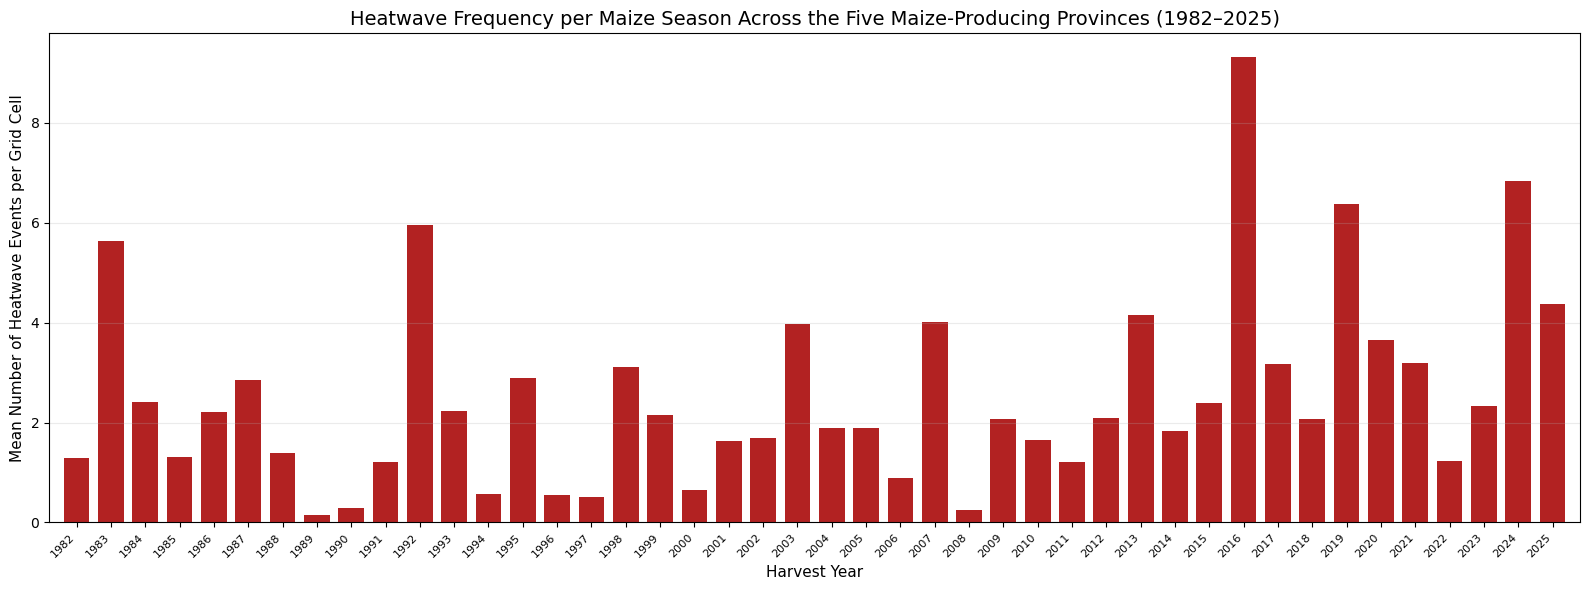

Saved:
C:\Users\franc\heatwave_frequency_per_maize_season_1982_2025.png


In [9]:
# ============================================================
# HEATWAVE FREQUENCY PER MAIZE SEASON
# ============================================================

years = hw_frequency_region["harvest_year"].values
frequency = hw_frequency_region.values

fig, ax = plt.subplots(figsize=(16, 6))

ax.bar(
    years,
    frequency,
    color="firebrick",
    width=0.75
)

# ============================================================
# LABELS
# ============================================================

ax.set_title(
    "Heatwave Frequency per Maize Season Across the Five Maize-Producing Provinces (1982–2025)",
    fontsize=14
)

ax.set_xlabel("Harvest Year", fontsize=11)

ax.set_ylabel(
    "Mean Number of Heatwave Events per Grid Cell",
    fontsize=11
)

# Show every harvest year
ax.set_xticks(years)
ax.set_xticklabels(
    years.astype(int),
    rotation=45,
    ha="right",
    fontsize=8
)

ax.set_xlim(years.min() - 0.8, years.max() + 0.8)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

# ============================================================
# SAVE PNG ONLY
# ============================================================

output_path = r"C:\Users\franc\heatwave_frequency_per_maize_season_1982_2025.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_path)

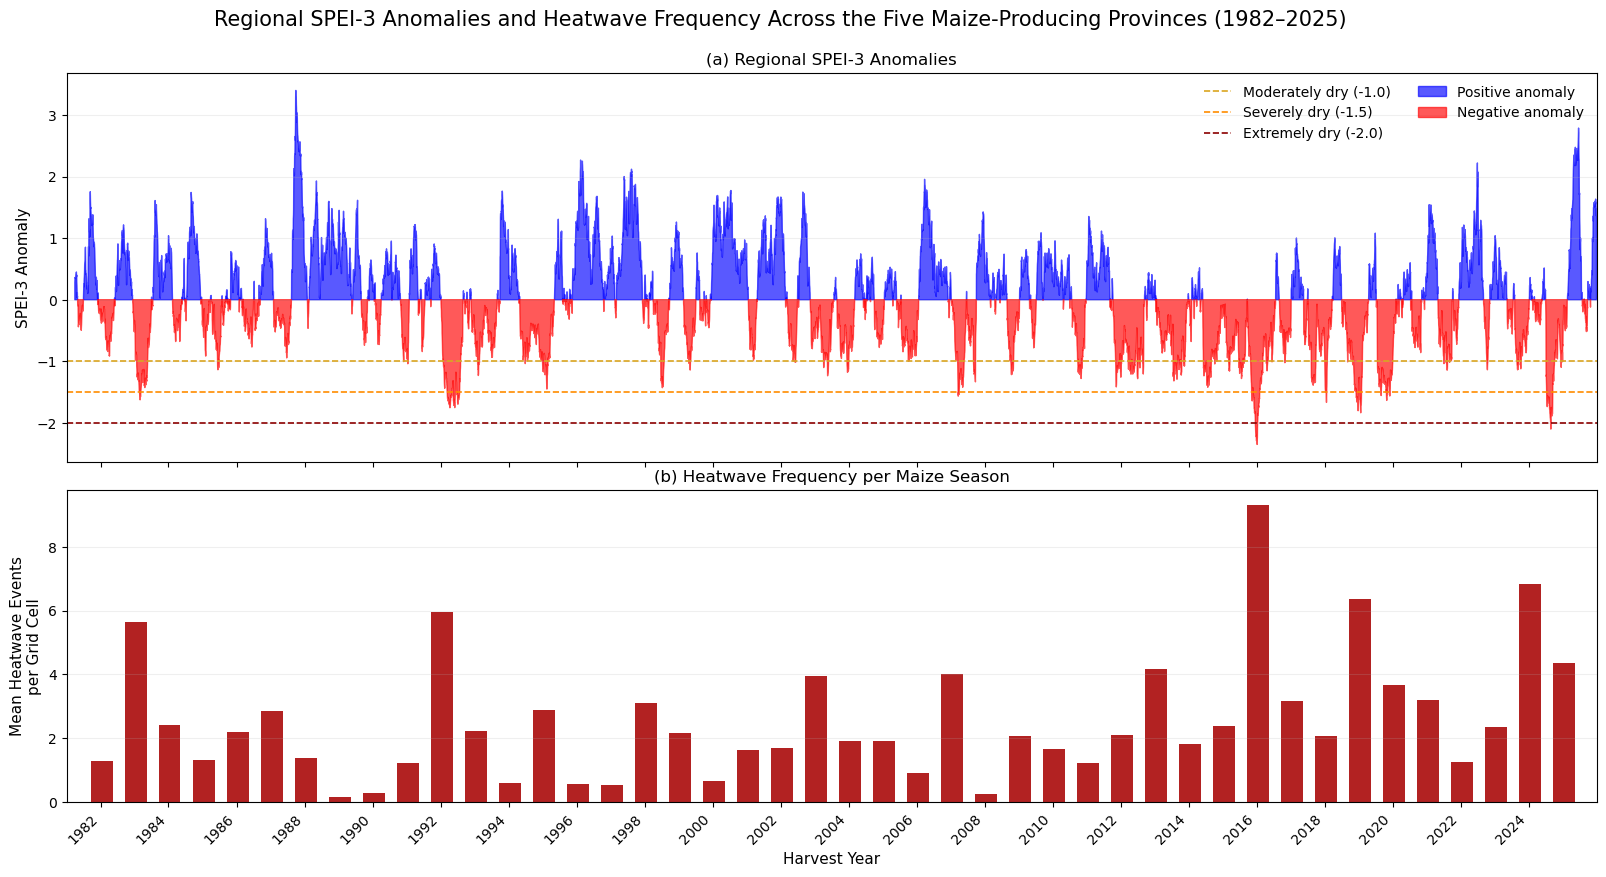

Saved:
C:\Users\franc\spei3_anomaly_heatwave_frequency_combined_1982_2025.png


In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ============================================================
# SPEI-3 ANOMALY DATA
# ============================================================

spei_time = pd.to_datetime(spei3_anomaly["time"].values)
spei_values = spei3_anomaly.values

# ============================================================
# HEATWAVE FREQUENCY DATA
# ============================================================

hw_years = hw_frequency_region["harvest_year"].values.astype(int)
hw_values = hw_frequency_region.values

# Position each bar near the middle of the Oct-Apr maize season
hw_dates = pd.to_datetime(
    [f"{year}-01-15" for year in hw_years]
)

# ============================================================
# COMBINED FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(17, 9),
    sharex=True,
    gridspec_kw={
        "height_ratios": [1.25, 1],
        "hspace": 0.08
    }
)

# ============================================================
# PANEL (a): SPEI-3 ANOMALIES
# ============================================================

ax1.axhline(-1.0, color="goldenrod", linestyle="--", linewidth=1.2,
            label="Moderately dry (-1.0)")

ax1.axhline(-1.5, color="darkorange", linestyle="--", linewidth=1.2,
            label="Severely dry (-1.5)")

ax1.axhline(-2.0, color="darkred", linestyle="--", linewidth=1.2,
            label="Extremely dry (-2.0)")
ax1.fill_between(
    spei_time,
    0,
    spei_values,
    where=(spei_values >= 0),
    interpolate=True,
    color="blue",
    alpha=0.65,
    label="Positive anomaly"
)

ax1.fill_between(
    spei_time,
    0,
    spei_values,
    where=(spei_values < 0),
    interpolate=True,
    color="red",
    alpha=0.65,
    label="Negative anomaly"
)

ax1.set_ylabel(
    "SPEI-3 Anomaly",
    fontsize=11
)

ax1.set_title(
    "(a) Regional SPEI-3 Anomalies",
    fontsize=12
)

ax1.legend(
    loc="upper right",
    frameon=False,
    ncol=2
)

ax1.grid(
    axis="y",
    alpha=0.20
)

# ============================================================
# PANEL (b): HEATWAVE FREQUENCY
# ============================================================

ax2.bar(
    hw_dates,
    hw_values,
    width=230,          # width in days
    color="firebrick"
)

ax2.set_ylabel(
    "Mean Heatwave Events\nper Grid Cell",
    fontsize=11
)

ax2.set_xlabel(
    "Harvest Year",
    fontsize=11
)

ax2.set_title(
    "(b) Heatwave Frequency per Maize Season",
    fontsize=12
)

ax2.grid(
    axis="y",
    alpha=0.20
)

# ============================================================
# SHARED X-AXIS
# ============================================================

tick_years = np.arange(1982, 2026, 2)

tick_dates = pd.to_datetime(
    [f"{year}-01-01" for year in tick_years]
)

ax2.set_xticks(tick_dates)

ax2.set_xticklabels(
    tick_years,
    rotation=45,
    ha="right"
)

ax1.set_xlim(
    pd.Timestamp("1981-01-01"),
    pd.Timestamp("2025-12-31")
)

# ============================================================
# OVERALL TITLE
# ============================================================

fig.suptitle(
    "Regional SPEI-3 Anomalies and Heatwave Frequency Across the Five "
    "Maize-Producing Provinces (1982–2025)",
    fontsize=15,
    y=0.98
)

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.91,
    bottom=0.10
)

# ============================================================
# SAVE PNG ONLY
# ============================================================

output_path = (
    r"C:\Users\franc\spei3_anomaly_heatwave_frequency_"
    r"combined_1982_2025.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_path)

In [11]:
import xarray as xr
import os

file_path = r"C:\Users\franc\cdhw_daily_mask_1981_2025.nc"

ds = xr.open_dataset(file_path, decode_timedelta=False)

print("File exists:", os.path.exists(file_path))

print("\nDimensions:")
for dim, size in ds.sizes.items():
    print(f"  {dim}: {size}")

print("\nCoordinates:")
for coord in ds.coords:
    print(f"  {coord}")

print("\nVariables:")
for var in ds.data_vars:
    print(f"  {var}")
    print("     dims :", ds[var].dims)
    print("     shape:", ds[var].shape)
    print("     attrs:", ds[var].attrs)

File exists: True

Dimensions:
  time: 16436
  latitude: 57
  longitude: 89

Coordinates:
  time
  latitude
  longitude
  number

Variables:
  cdhw_active
     dims : ('time', 'latitude', 'longitude')
     shape: (16436, 57, 89)
     attrs: {'long_name': 'Daily simultaneous compound drought-heatwave active mask', 'description': '1 = flash drought and heatwave active simultaneously at the same grid cell and day; 0 = otherwise'}


In [12]:
import os

folder = r"C:\Users\franc"

keywords = ["heat", "hw", "drought", "flash", "cdhw"]

nc_files = [
    f for f in os.listdir(folder)
    if f.lower().endswith(".nc")
]

print("Possible relevant NetCDF files:\n")

for f in sorted(nc_files):
    if any(word in f.lower() for word in keywords):
        print(f)

Possible relevant NetCDF files:

cdhw_daily_mask_1981_2025.nc
cdhw_longterm_spatial_summary_1982_2025.nc
cdhw_severity_1982_2025.nc
compound_flash_drought_duration_1982_2025.nc
compound_heatwave_duration_1982_2025.nc
flash_drought_daily_mask_1981_2025.nc
flash_drought_events_1982_2025.nc
flash_drought_events_1982_2025_final.nc
flash_drought_events_1982_2025_fixed.nc
flash_drought_metrics_1982_2025.nc
heatwave_daily_mask_1981_2025.nc
hw_duration_return_levels_20_50_100yr.nc
hw_frequency_return_levels_20_50_100yr.nc
rq1_cdhw_return_periods_1982_2025.nc
rq1_cdhw_return_periods_1982_2025_corrected.nc
rq1_cdhw_temporal_summary_1982_2025.nc
south_africa_maize_season_heatwaves_1981_2025.nc
south_africa_maize_season_heatwaves_1981_2025_updated.nc
spam2020_maize_area_cdhw_grid_final.nc
spam2020_maize_variables_cdhw_grid_final.nc
spam2020_sa_maize_mask_cdhw_grid.nc


In [13]:
import xarray as xr

files = {
    "Heatwave": r"C:\Users\franc\heatwave_daily_mask_1981_2025.nc",
    "Flash drought": r"C:\Users\franc\flash_drought_daily_mask_1981_2025.nc"
}

for name, path in files.items():

    ds = xr.open_dataset(path, decode_timedelta=False)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Dimensions:")
    for dim, size in ds.sizes.items():
        print(f"  {dim}: {size}")

    print("\nVariables:")
    for var in ds.data_vars:
        print(f"  {var}")
        print("     dims :", ds[var].dims)
        print("     shape:", ds[var].shape)
        print("     attrs:", ds[var].attrs)

    print("\nTime:")
    if "time" in ds.coords:
        print("  Start:", ds.time.values[0])
        print("  End:  ", ds.time.values[-1])


Heatwave
Dimensions:
  time: 16436
  latitude: 57
  longitude: 89

Variables:
  heatwave_active
     dims : ('time', 'latitude', 'longitude')
     shape: (16436, 57, 89)
     attrs: {'long_name': 'Daily agricultural heatwave active mask', 'description': '1 = daily Tmax exceeds the localized 90th percentile for at least 3 consecutive days during the South African maize growing season; 0 = otherwise'}

Time:
  Start: 1981-01-01T00:00:00.000000000
  End:   2025-12-31T00:00:00.000000000

Flash drought
Dimensions:
  time: 16436
  lat: 141
  lon: 220

Variables:
  flash_drought_active
     dims : ('time', 'lat', 'lon')
     shape: (16436, 141, 220)
     attrs: {'long_name': 'Daily flash drought active mask', 'description': '1 = active flash drought event, 0 = no active flash drought'}

Time:
  Start: 1981-01-01T00:00:00.000000000
  End:   2025-12-31T00:00:00.000000000


In [14]:
import xarray as xr
import numpy as np

hw = xr.open_dataset(
    r"C:\Users\franc\heatwave_daily_mask_1981_2025.nc",
    decode_timedelta=False
)

fd = xr.open_dataset(
    r"C:\Users\franc\flash_drought_daily_mask_1981_2025.nc",
    decode_timedelta=False
)

cdhw = xr.open_dataset(
    r"C:\Users\franc\cdhw_daily_mask_1981_2025.nc",
    decode_timedelta=False
)

print("HEATWAVE GRID")
print("Latitude :", float(hw.latitude.min()), "to", float(hw.latitude.max()))
print("Longitude:", float(hw.longitude.min()), "to", float(hw.longitude.max()))
print("Resolution:")
print("  lat:", np.abs(np.diff(hw.latitude.values)).mean())
print("  lon:", np.abs(np.diff(hw.longitude.values)).mean())

print("\nFLASH-DROUGHT GRID")
print("Latitude :", float(fd.lat.min()), "to", float(fd.lat.max()))
print("Longitude:", float(fd.lon.min()), "to", float(fd.lon.max()))
print("Resolution:")
print("  lat:", np.abs(np.diff(fd.lat.values)).mean())
print("  lon:", np.abs(np.diff(fd.lon.values)).mean())

print("\nCDHW GRID")
print("Latitude :", float(cdhw.latitude.min()), "to", float(cdhw.latitude.max()))
print("Longitude:", float(cdhw.longitude.min()), "to", float(cdhw.longitude.max()))
print("Resolution:")
print("  lat:", np.abs(np.diff(cdhw.latitude.values)).mean())
print("  lon:", np.abs(np.diff(cdhw.longitude.values)).mean())

print("\nDoes CDHW use exactly the heatwave grid?")
print(
    "Latitude:",
    np.array_equal(cdhw.latitude.values, hw.latitude.values)
)
print(
    "Longitude:",
    np.array_equal(cdhw.longitude.values, hw.longitude.values)
)

HEATWAVE GRID
Latitude : -35.0 to -21.0
Longitude: 11.0 to 33.0
Resolution:
  lat: 0.25
  lon: 0.25

FLASH-DROUGHT GRID
Latitude : -34.95000000000313 to -20.950000000003925
Longitude: 11.049999999989154 to 32.94999999998791
Resolution:
  lat: 0.09999999999999432
  lon: 0.09999999999999432

CDHW GRID
Latitude : -35.0 to -21.0
Longitude: 11.0 to 33.0
Resolution:
  lat: 0.25
  lon: 0.25

Does CDHW use exactly the heatwave grid?
Latitude: False
Longitude: True


In [15]:
import xarray as xr
import geopandas as gpd
import numpy as np
from shapely.geometry import Point

# ============================================================
# FILES
# ============================================================

hw_file = r"C:\Users\franc\heatwave_daily_mask_1981_2025.nc"
fd_file = r"C:\Users\franc\flash_drought_daily_mask_1981_2025.nc"

province_file = r"C:\Users\franc\South_Africa_Provinces\South_Africa_Provinces.gpkg"

study_provinces = [
    "Free State",
    "North West",
    "Mpumalanga",
    "Gauteng",
    "KwaZulu-Natal"
]

# ============================================================
# OPEN DATA
# ============================================================

hw = xr.open_dataset(hw_file, decode_timedelta=False)
fd = xr.open_dataset(fd_file, decode_timedelta=False)

# ============================================================
# READ STUDY PROVINCES
# ============================================================

provinces = gpd.read_file(province_file)

study = provinces[
    provinces["ProvinceName"].isin(study_provinces)
].to_crs("EPSG:4326")

study_geometry = study.geometry.union_all()

# ============================================================
# FUNCTION TO CREATE GRID MASK
# ============================================================

def make_mask(latitudes, longitudes, geometry):

    mask = np.zeros(
        (len(latitudes), len(longitudes)),
        dtype=bool
    )

    for i, lat in enumerate(latitudes):
        for j, lon in enumerate(longitudes):

            if geometry.covers(Point(float(lon), float(lat))):
                mask[i, j] = True

    return mask


# ============================================================
# HEATWAVE MASK
# ============================================================

hw_region_mask = make_mask(
    hw.latitude.values,
    hw.longitude.values,
    study_geometry
)

print("Heatwave grid cells inside study region:",
      hw_region_mask.sum())


# ============================================================
# FLASH-DROUGHT MASK
# ============================================================

fd_region_mask = make_mask(
    fd.lat.values,
    fd.lon.values,
    study_geometry
)

print("Flash-drought grid cells inside study region:",
      fd_region_mask.sum())


# ============================================================
# REGIONAL DAILY FRACTION
# ============================================================

hw_mask_da = xr.DataArray(
    hw_region_mask,
    coords={
        "latitude": hw.latitude,
        "longitude": hw.longitude
    },
    dims=("latitude", "longitude")
)

fd_mask_da = xr.DataArray(
    fd_region_mask,
    coords={
        "lat": fd.lat,
        "lon": fd.lon
    },
    dims=("lat", "lon")
)


hw_daily_fraction = (
    hw["heatwave_active"]
    .where(hw_mask_da)
    .mean(dim=("latitude", "longitude"))
)


fd_daily_fraction = (
    fd["flash_drought_active"]
    .where(fd_mask_da)
    .mean(dim=("lat", "lon"))
)


# ============================================================
# CHECK
# ============================================================

print("\nDaily series created successfully.")

print("\nHeatwave:")
print("Start:", hw_daily_fraction.time.values[0])
print("End:  ", hw_daily_fraction.time.values[-1])
print("Maximum affected fraction:",
      float(hw_daily_fraction.max()))

print("\nFlash drought:")
print("Start:", fd_daily_fraction.time.values[0])
print("End:  ", fd_daily_fraction.time.values[-1])
print("Maximum affected fraction:",
      float(fd_daily_fraction.max()))

Heatwave grid cells inside study region: 619
Flash-drought grid cells inside study region: 3865

Daily series created successfully.

Heatwave:
Start: 1981-01-01T00:00:00.000000000
End:   2025-12-31T00:00:00.000000000
Maximum affected fraction: 0.9628432989120483

Flash drought:
Start: 1981-01-01T00:00:00.000000000
End:   2025-12-31T00:00:00.000000000
Maximum affected fraction: 0.9327296018600464


In [17]:
import xarray as xr

severity_file = r"C:\Users\franc\cdhw_severity_1982_2025.nc"

sev = xr.open_dataset(
    severity_file,
    decode_timedelta=False
)

print("Dimensions:")
print(dict(sev.sizes))

print("\nCoordinates:")
print(list(sev.coords))

print("\nVariables:")
print(list(sev.data_vars))

print("\nCumulative severity:")
x = sev["cdhw_cumulative_severity"]

print("Dimensions:", x.dims)
print("Shape:", x.shape)
print("Min:", float(x.min()))
print("Max:", float(x.max()))
print("Mean:", float(x.mean()))

Dimensions:
{'harvest_year': 44, 'latitude': 57, 'longitude': 89}

Coordinates:
['number', 'latitude', 'longitude', 'harvest_year']

Variables:
['cdhw_simultaneous_days', 'cdhw_heat_intensity', 'cdhw_drought_intensity', 'cdhw_cumulative_severity', 'cdhw_peak_severity', 'cdhw_mean_severity']

Cumulative severity:
Dimensions: ('harvest_year', 'latitude', 'longitude')
Shape: (44, 57, 89)
Min: 0.0
Max: 428.4055656580013
Mean: 3.9626536605839227


Grid cells inside five provinces: 619

Compound severity by maize season:

1982: 0.193
1983: 39.881
1984: 7.805
1985: 0.872
1986: 0.262
1987: 1.585
1988: 0.020
1989: 0.003
1990: 0.010
1991: 0.416
1992: 39.759
1993: 6.175
1994: 0.014
1995: 9.171
1996: 0.009
1997: 0.006
1998: 3.208
1999: 1.404
2000: 0.000
2001: 0.258
2002: 1.078
2003: 2.332
2004: 1.693
2005: 0.527
2006: 0.213
2007: 7.244
2008: 0.040
2009: 0.120
2010: 0.024
2011: 0.163
2012: 5.309
2013: 2.952
2014: 0.867
2015: 2.945
2016: 118.865
2017: 0.861
2018: 6.939
2019: 59.390
2020: 30.246
2021: 1.674
2022: 0.098
2023: 0.083
2024: 3.556
2025: 7.730

Highest severity seasons:
2016: 118.865
2019: 59.390
1983: 39.881
1992: 39.759
2020: 30.246
1995: 9.171
1984: 7.805
2025: 7.730
2007: 7.244
2018: 6.939


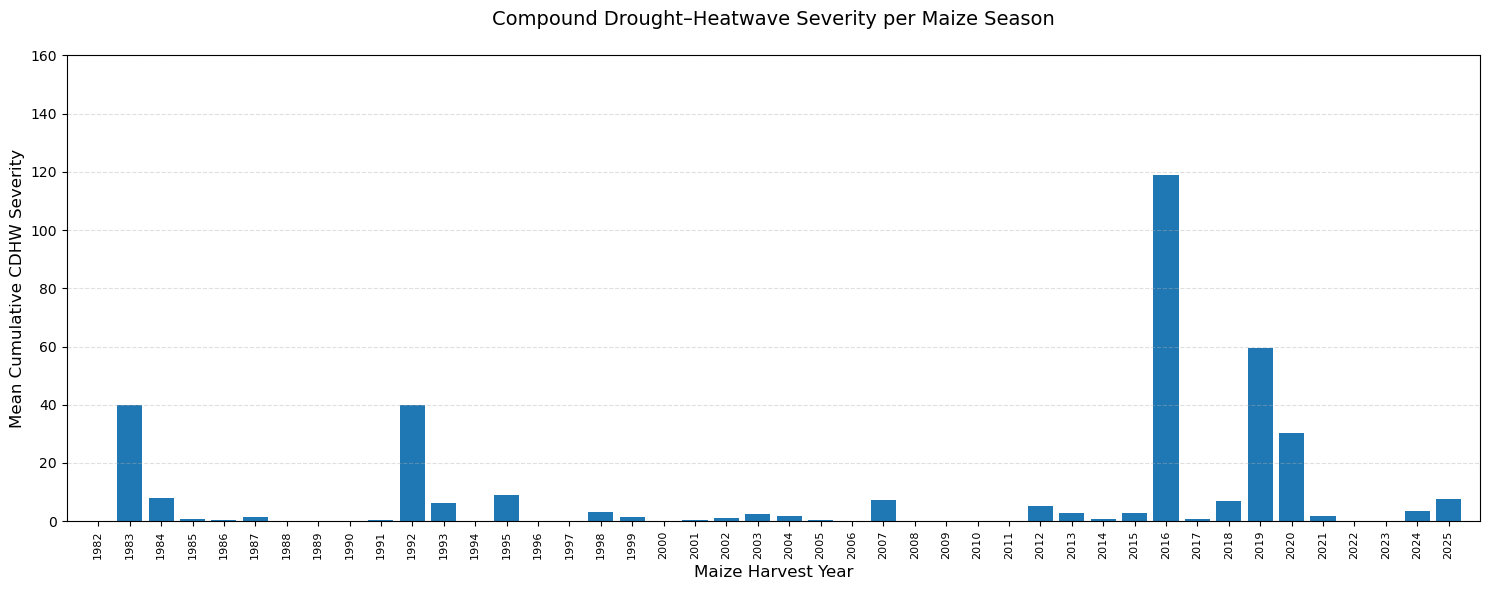


Saved to:
C:\Users\franc\compound_severity_per_maize_season_1982_2025.png


In [18]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# COMPOUND EVENT SEVERITY PER MAIZE SEASON
# Five maize-producing provinces
# 1982–2025
# ============================================================

# Compound cumulative severity
severity = sev["cdhw_cumulative_severity"]


# ============================================================
# 1. CREATE FIVE-PROVINCE MASK ON SEVERITY GRID
# ============================================================

region_mask = xr.DataArray(
    hw_region_mask,
    coords={
        "latitude": severity.latitude,
        "longitude": severity.longitude
    },
    dims=("latitude", "longitude")
)

print(
    "Grid cells inside five provinces:",
    int(region_mask.sum())
)


# ============================================================
# 2. MASK OUT AREAS OUTSIDE STUDY REGION
# ============================================================

severity_region = severity.where(region_mask)


# ============================================================
# 3. REGIONAL MEAN FOR EACH HARVEST YEAR
# ============================================================

severity_annual = severity_region.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

years = severity_annual.harvest_year.values.astype(int)
values = severity_annual.values


# ============================================================
# 4. PRINT RESULTS
# ============================================================

print("\nCompound severity by maize season:\n")

for year, value in zip(years, values):
    print(
        f"{year}: {value:.3f}"
    )


print("\nHighest severity seasons:")

top_idx = np.argsort(values)[::-1][:10]

for i in top_idx:
    print(
        f"{years[i]}: {values[i]:.3f}"
    )


# ============================================================
# 5. BAR CHART
# ============================================================

fig, ax = plt.subplots(
    figsize=(15, 6)
)

ax.bar(
    years,
    values,
    width=0.8
)

ax.set_ylim(0, 160)

ax.set_xlabel(
    "Maize Harvest Year",
    fontsize=12
)

ax.set_ylabel(
    "Mean Cumulative CDHW Severity",
    fontsize=12
)

ax.set_title(
    "Compound Drought–Heatwave Severity per Maize Season\n",
    fontsize=14
)

ax.set_xticks(years)

ax.set_xticklabels(
    years,
    rotation=90,
    fontsize=8
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_xlim(
    years.min() - 1,
    years.max() + 1
)

plt.tight_layout()


# ============================================================
# 6. SAVE AS PNG
# ============================================================

output_file = (
    r"C:\Users\franc\compound_severity_per_maize_season_1982_2025.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved to:")
print(output_file)

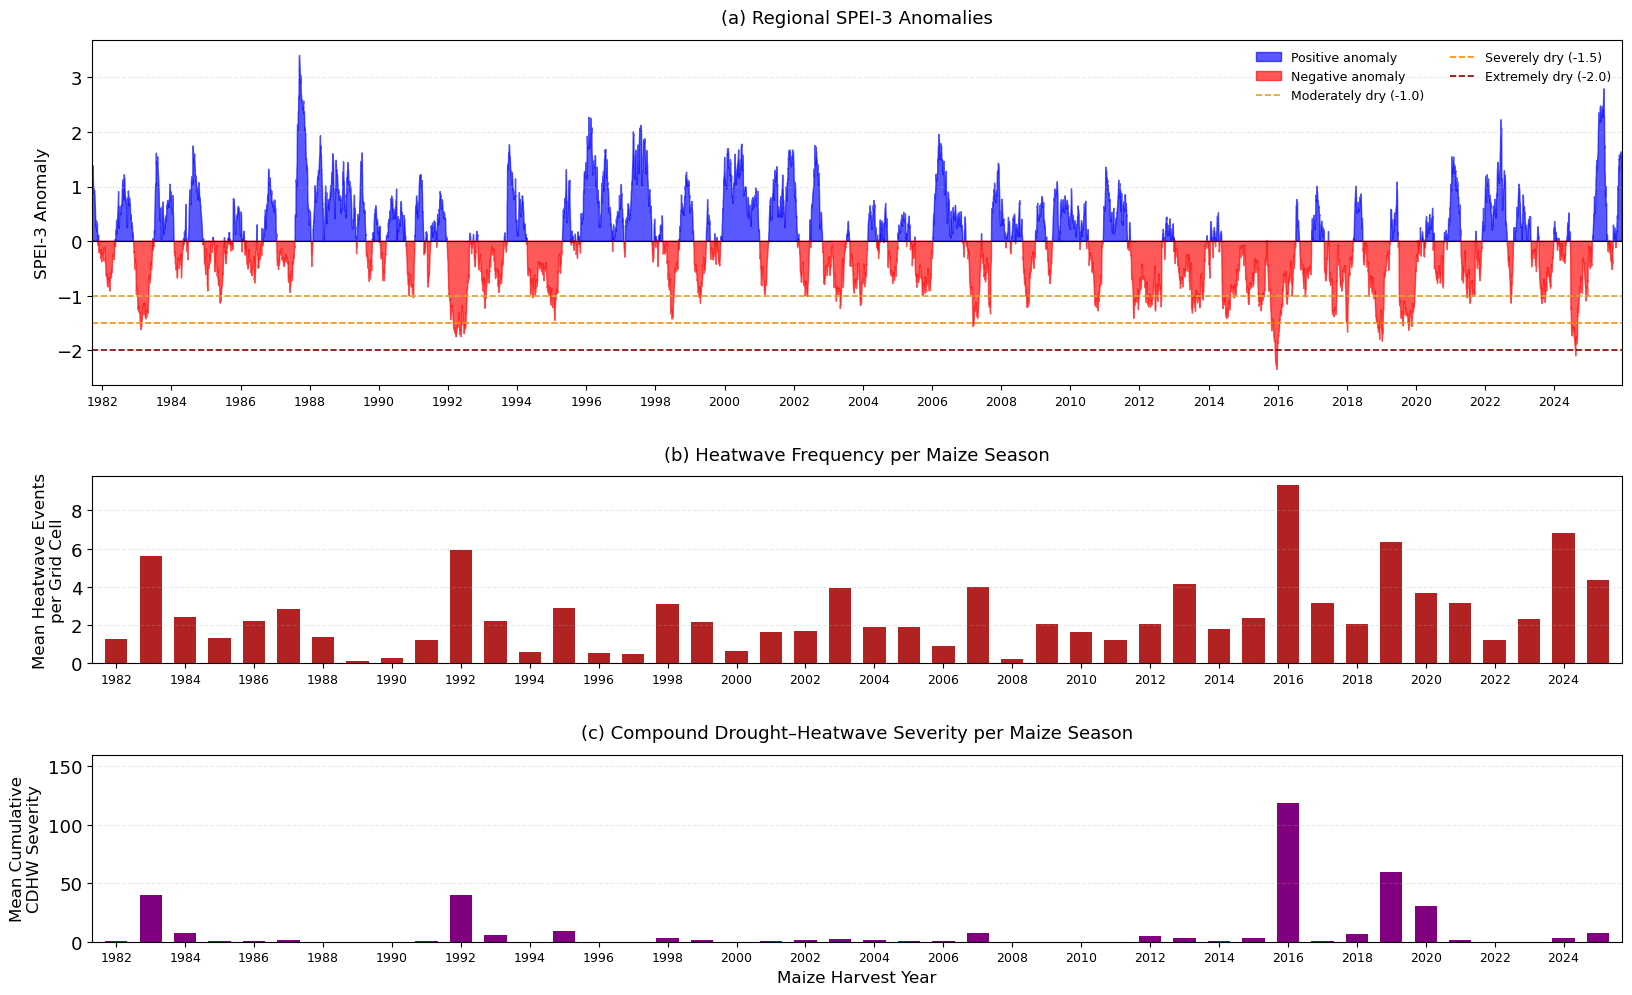

Saved to:
C:\Users\franc\spei3_heatwave_compound_severity_combined_1982_2025_NEAT.png


In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ============================================================
# CLEAN THREE-PANEL FIGURE
# ============================================================

fig, (ax1, ax2, ax3) = plt.subplots(
    3,
    1,
    figsize=(17, 11),
    gridspec_kw={
        "height_ratios": [2.4, 1.3, 1.3],
        "hspace": 0.38
    }
)

# ============================================================
# PANEL (a): REGIONAL SPEI-3 ANOMALIES
# ============================================================

spei_time = pd.to_datetime(
    spei3_anomaly.time.values
)

spei_values = spei3_anomaly.values

ax1.fill_between(
    spei_time,
    0,
    spei_values,
    where=(spei_values >= 0),
    interpolate=True,
    color="blue",
    alpha=0.65,
    label="Positive anomaly"
)

ax1.fill_between(
    spei_time,
    0,
    spei_values,
    where=(spei_values < 0),
    interpolate=True,
    color="red",
    alpha=0.65,
    label="Negative anomaly"
)

ax1.axhline(
    0,
    color="black",
    linewidth=0.8
)

ax1.axhline(
    -1.0,
    color="goldenrod",
    linestyle="--",
    linewidth=1.2,
    label="Moderately dry (-1.0)"
)

ax1.axhline(
    -1.5,
    color="darkorange",
    linestyle="--",
    linewidth=1.2,
    label="Severely dry (-1.5)"
)

ax1.axhline(
    -2.0,
    color="darkred",
    linestyle="--",
    linewidth=1.2,
    label="Extremely dry (-2.0)"
)

ax1.set_ylabel(
    "SPEI-3 Anomaly",
    fontsize=12
)

ax1.set_title(
    "(a) Regional SPEI-3 Anomalies",
    fontsize=13,
    pad=12
)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax1.legend(
    loc="upper right",
    ncol=2,
    fontsize=9,
    frameon=False
)

ax1.set_xlim(
    pd.Timestamp("1981-10-01"),
    pd.Timestamp("2025-12-31")
)


# ============================================================
# PANEL (b): HEATWAVE FREQUENCY
# ============================================================

hw_years = (
    hw_frequency_region
    .harvest_year
    .values
    .astype(int)
)

hw_values = (
    hw_frequency_region
    .values
)

ax2.bar(
    hw_years,
    hw_values,
    width=0.65,
    color="firebrick"
)

ax2.set_ylabel(
    "Mean Heatwave Events\nper Grid Cell",
    fontsize=12
)

ax2.set_title(
    "(b) Heatwave Frequency per Maize Season",
    fontsize=13,
    pad=12
)

ax2.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax2.set_xlim(
    1981.3,
    2025.7
)


# ============================================================
# PANEL (c): COMPOUND SEVERITY
# ============================================================

severity_years = (
    severity_annual
    .harvest_year
    .values
    .astype(int)
)

severity_values = (
    severity_annual
    .values
)

ax3.bar(
    severity_years,
    severity_values,
    width=0.65,
    color="purple"
)

ax3.set_ylim(
    0,
    160
)

ax3.set_xlim(
    1981.3,
    2025.7
)

ax3.set_ylabel(
    "Mean Cumulative\nCDHW Severity",
    fontsize=12
)

ax3.set_title(
    "(c) Compound Drought–Heatwave Severity per Maize Season",
    fontsize=13,
    pad=12
)

ax3.set_xlabel(
    "Maize Harvest Year",
    fontsize=12
)

ax3.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)


# ============================================================
# X-AXIS TICKS
# ============================================================

# Use labels every 2 years only
tick_years = np.arange(
    1982,
    2026,
    2
)

# Panel (a) uses dates
tick_dates = [
    pd.Timestamp(
        year=int(year),
        month=1,
        day=15
    )
    for year in tick_years
]

ax1.set_xticks(
    tick_dates
)

ax1.set_xticklabels(
    tick_years,
    rotation=0,
    fontsize=9
)

# Panels (b) and (c) use integer years
ax2.set_xticks(
    tick_years
)

ax2.set_xticklabels(
    tick_years,
    rotation=0,
    fontsize=9
)

ax3.set_xticks(
    tick_years
)

ax3.set_xticklabels(
    tick_years,
    rotation=0,
    fontsize=9
)


# ============================================================
# FONT SIZE FOR Y-AXES
# ============================================================

for ax in [ax1, ax2, ax3]:
    ax.tick_params(
        axis="y",
        labelsize=13
    )


# ============================================================
# MAIN TITLE
# ============================================================

'''fig.suptitle(
    "Regional SPEI-3 Anomalies, Heatwave Frequency, and "
    "Compound Drought–Heatwave Severity\n"
    "Across the Five Maize-Producing Provinces (1982–2025)",
    fontsize=16,
    y=0.985
)'''


# ============================================================
# LAYOUT
# ============================================================

plt.subplots_adjust(
    top=0.90,
    bottom=0.08,
    left=0.08,
    right=0.98,
    hspace=0.40
)


# ============================================================
# SAVE
# ============================================================

output_file = (
    r"C:\Users\franc"
    r"\spei3_heatwave_compound_severity_combined_1982_2025_NEAT.png"
)

plt.savefig(
    output_file,
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:")
print(output_file)

In [20]:
# Show likely variables currently in memory
[name for name in globals().keys()
 if any(word in name.lower() for word in
        ["spei", "anomaly", "heatwave", "frequency", "severity"])]

['spei_path',
 'spei3_study',
 'spei3_region_mean',
 'spei3_climatological_mean',
 'spei3_anomaly',
 'hw_frequency_study',
 'hw_frequency_region',
 'frequency',
 'spei_time',
 'spei_values',
 'severity_file',
 'severity',
 'severity_region',
 'severity_annual',
 'severity_years',
 'severity_values']

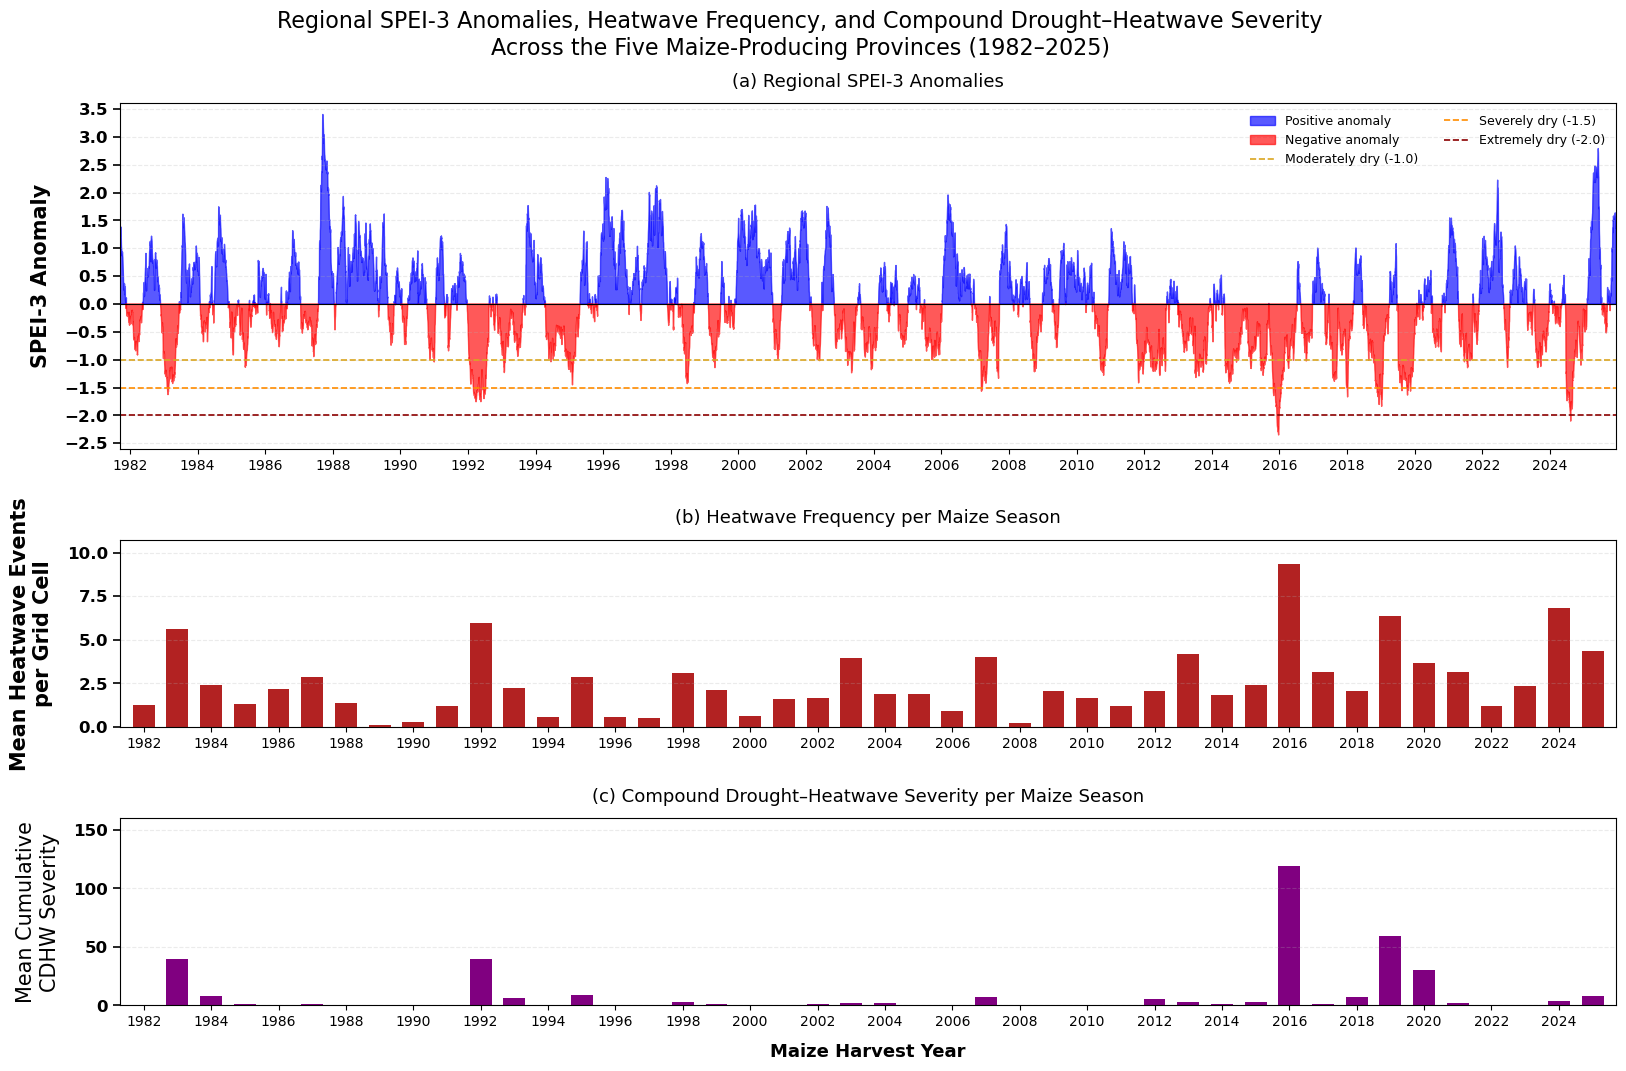

Saved to:
C:\Users\franc\spei3_heatwave_compound_severity_combined_1982_2025_NEAT.png


In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ============================================================
# CLEAN THREE-PANEL FIGURE
# ============================================================

fig, (ax1, ax2, ax3) = plt.subplots(
    3,
    1,
    figsize=(17, 11),
    gridspec_kw={
        "height_ratios": [2.4, 1.3, 1.3],
        "hspace": 0.38
    }
)

# ============================================================
# PANEL (a): REGIONAL SPEI-3 ANOMALIES
# ============================================================

spei_time = pd.to_datetime(spei3_anomaly.time.values)
spei_values = spei3_anomaly.values

ax1.fill_between(
    spei_time,
    0,
    spei_values,
    where=(spei_values >= 0),
    interpolate=True,
    color="blue",
    alpha=0.65,
    label="Positive anomaly"
)

ax1.fill_between(
    spei_time,
    0,
    spei_values,
    where=(spei_values < 0),
    interpolate=True,
    color="red",
    alpha=0.65,
    label="Negative anomaly"
)

ax1.axhline(
    0,
    color="black",
    linewidth=0.8
)

ax1.axhline(
    -1.0,
    color="goldenrod",
    linestyle="--",
    linewidth=1.2,
    label="Moderately dry (-1.0)"
)

ax1.axhline(
    -1.5,
    color="darkorange",
    linestyle="--",
    linewidth=1.2,
    label="Severely dry (-1.5)"
)

ax1.axhline(
    -2.0,
    color="darkred",
    linestyle="--",
    linewidth=1.2,
    label="Extremely dry (-2.0)"
)

ax1.set_ylabel(
    "SPEI-3 Anomaly",
    fontsize=15,
    fontweight="bold",
    labelpad=10
)

ax1.set_title(
    "(a) Regional SPEI-3 Anomalies",
    fontsize=13,
    pad=12
)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax1.legend(
    loc="upper right",
    ncol=2,
    fontsize=9,
    frameon=False
)

ax1.set_xlim(
    pd.Timestamp("1981-10-01"),
    pd.Timestamp("2025-12-31")
)

# Explicitly include -1.5 among the SPEI-3 y-axis labels
spei_lower = np.floor(np.nanmin(spei_values) * 2) / 2
spei_upper = np.ceil(np.nanmax(spei_values) * 2) / 2

spei_lower = min(spei_lower, -2.0)
spei_upper = max(spei_upper, 1.0)

spei_yticks = np.arange(
    spei_lower,
    spei_upper + 0.25,
    0.5
)

ax1.set_ylim(
    spei_lower - 0.1,
    spei_upper + 0.1
)

ax1.set_yticks(spei_yticks)


# ============================================================
# PANEL (b): HEATWAVE FREQUENCY
# ============================================================

hw_years = (
    hw_frequency_region
    .harvest_year
    .values
    .astype(int)
)

hw_values = hw_frequency_region.values

ax2.bar(
    hw_years,
    hw_values,
    width=0.65,
    color="firebrick"
)

ax2.set_ylabel(
    "Mean Heatwave Events\nper Grid Cell",
    fontsize=15,
    fontweight="bold",
    labelpad=10
)

ax2.set_title(
    "(b) Heatwave Frequency per Maize Season",
    fontsize=13,
    pad=12
)

ax2.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax2.set_xlim(
    1981.3,
    2025.7
)

# Add a little space above the tallest bar
ax2.set_ylim(
    0,
    np.nanmax(hw_values) * 1.15
)


# ============================================================
# PANEL (c): COMPOUND SEVERITY
# ============================================================

severity_years = (
    severity_annual
    .harvest_year
    .values
    .astype(int)
)

severity_values = severity_annual.values

ax3.bar(
    severity_years,
    severity_values,
    width=0.65,
    color="purple"
)

ax3.set_ylim(
    0,
    160
)

ax3.set_xlim(
    1981.3,
    2025.7
)

ax3.set_ylabel(
    "Mean Cumulative\nCDHW Severity",
    fontsize=15,
    #fontweight="bold",
    labelpad=10
)

ax3.set_title(
    "(c) Compound Drought–Heatwave Severity per Maize Season",
    fontsize=13,
    pad=12
)

ax3.set_xlabel(
    "Maize Harvest Year",
    fontsize=13,
    fontweight="bold",
    labelpad=10
)

ax3.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)


# ============================================================
# X-AXIS TICKS
# ============================================================

tick_years = np.arange(
    1982,
    2026,
    2
)

# Panel (a) uses dates
tick_dates = [
    pd.Timestamp(
        year=int(year),
        month=1,
        day=15
    )
    for year in tick_years
]

ax1.set_xticks(tick_dates)

ax1.set_xticklabels(
    tick_years,
    rotation=0,
    fontsize=10
)

# Panels (b) and (c) use integer years
ax2.set_xticks(tick_years)

ax2.set_xticklabels(
    tick_years,
    rotation=0,
    fontsize=10
)

ax3.set_xticks(tick_years)

ax3.set_xticklabels(
    tick_years,
    rotation=0,
    fontsize=10
)


# ============================================================
# INCREASE Y-AXIS TICK-LABEL VISIBILITY
# ============================================================

for ax in [ax1, ax2, ax3]:
    ax.tick_params(
        axis="y",
        labelsize=12,
        width=1.2,
        length=5
    )

    # Make all y-axis tick labels bold
    for label in ax.get_yticklabels():
        label.set_fontweight("bold")


# ============================================================
# MAIN TITLE
# ============================================================

fig.suptitle(
    "Regional SPEI-3 Anomalies, Heatwave Frequency, and "
    "Compound Drought–Heatwave Severity\n"
    "Across the Five Maize-Producing Provinces (1982–2025)",
    fontsize=16,
    y=0.985
)


# ============================================================
# LAYOUT
# ============================================================

plt.subplots_adjust(
    top=0.90,
    bottom=0.08,
    left=0.10,
    right=0.98,
    hspace=0.40
)


# ============================================================
# SAVE
# ============================================================

output_file = (
    r"C:\Users\franc"
    r"\spei3_heatwave_compound_severity_combined_1982_2025_NEAT.png"
)

plt.savefig(
    output_file,
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:")
print(output_file)

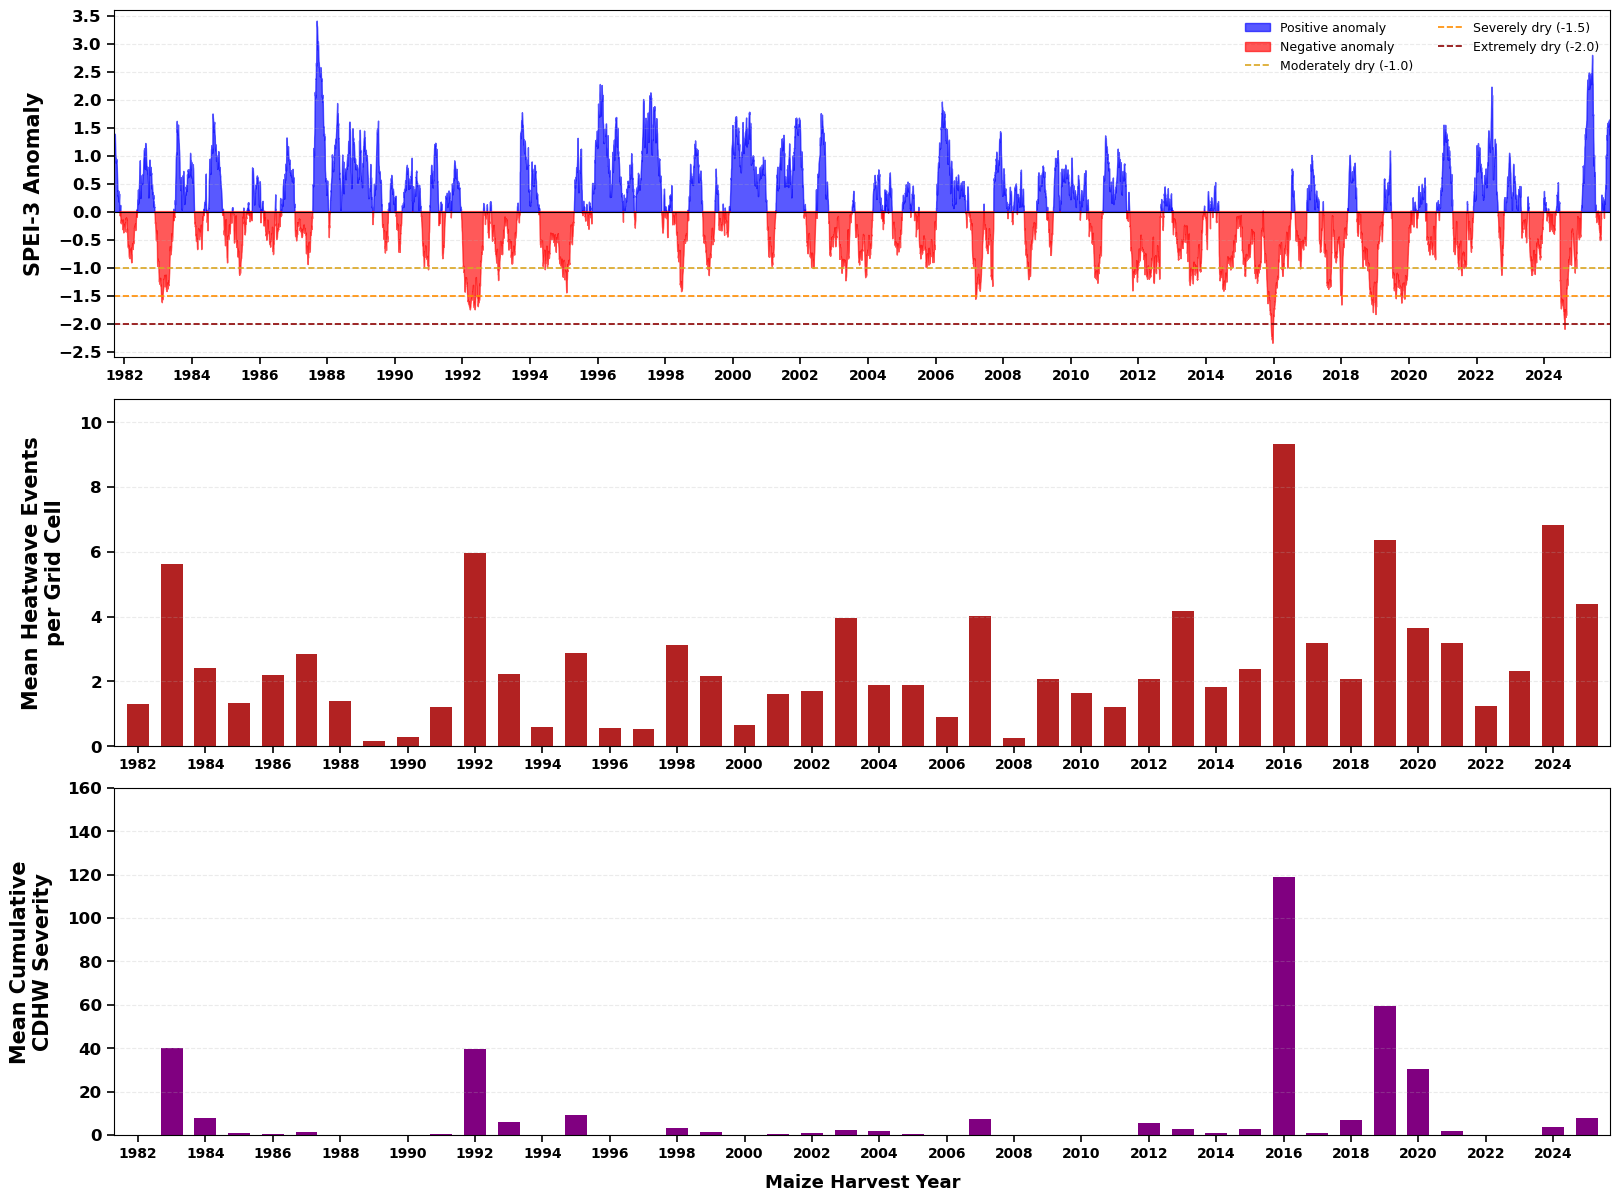

Saved to:
C:\Users\franc\spei3_heatwave_compound_severity_combined_1982_2025_NEAT.png


In [31]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ============================================================
# CLEAN THREE-PANEL FIGURE
# ============================================================

fig, (ax1, ax2, ax3) = plt.subplots(
    3,
    1,
    figsize=(17, 12.5),
    gridspec_kw={
        "height_ratios": [1, 1, 1],
        "hspace": 0.12
    }
)

# ============================================================
# PANEL (a): REGIONAL SPEI-3 ANOMALIES
# ============================================================

spei_time = pd.to_datetime(spei3_anomaly.time.values)
spei_values = spei3_anomaly.values

ax1.fill_between(
    spei_time,
    0,
    spei_values,
    where=(spei_values >= 0),
    interpolate=True,
    color="blue",
    alpha=0.65,
    label="Positive anomaly"
)

ax1.fill_between(
    spei_time,
    0,
    spei_values,
    where=(spei_values < 0),
    interpolate=True,
    color="red",
    alpha=0.65,
    label="Negative anomaly"
)

ax1.axhline(
    0,
    color="black",
    linewidth=0.8
)

ax1.axhline(
    -1.0,
    color="goldenrod",
    linestyle="--",
    linewidth=1.2,
    label="Moderately dry (-1.0)"
)

ax1.axhline(
    -1.5,
    color="darkorange",
    linestyle="--",
    linewidth=1.2,
    label="Severely dry (-1.5)"
)

ax1.axhline(
    -2.0,
    color="darkred",
    linestyle="--",
    linewidth=1.2,
    label="Extremely dry (-2.0)"
)

# ------------------------------------------------------------
# Axis title
# ------------------------------------------------------------

ax1.set_ylabel(
    "SPEI-3 Anomaly",
    fontsize=15,
    fontweight="semibold",
    labelpad=10
)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax1.legend(
    loc="upper right",
    ncol=2,
    fontsize=9,
    frameon=False
)

ax1.set_xlim(
    pd.Timestamp("1981-10-01"),
    pd.Timestamp("2025-12-31")
)

# Explicitly include -1.5 among the SPEI-3 y-axis labels
spei_lower = np.floor(np.nanmin(spei_values) * 2) / 2
spei_upper = np.ceil(np.nanmax(spei_values) * 2) / 2

spei_lower = min(spei_lower, -2.0)
spei_upper = max(spei_upper, 1.0)

spei_yticks = np.arange(
    spei_lower,
    spei_upper + 0.25,
    0.5
)

ax1.set_ylim(
    spei_lower - 0.1,
    spei_upper + 0.1
)

ax1.set_yticks(spei_yticks)


# ============================================================
# PANEL (b): HEATWAVE FREQUENCY
# ============================================================

hw_years = (
    hw_frequency_region
    .harvest_year
    .values
    .astype(int)
)

hw_values = hw_frequency_region.values

ax2.bar(
    hw_years,
    hw_values,
    width=0.65,
    color="firebrick"
)

# ------------------------------------------------------------
# Axis title
# ------------------------------------------------------------

ax2.set_ylabel(
    "Mean Heatwave Events\nper Grid Cell",
    fontsize=15,
    fontweight="semibold",
    labelpad=10
)

ax2.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax2.set_xlim(
    1981.3,
    2025.7
)

# Add space above the tallest bar
ax2.set_ylim(
    0,
    np.nanmax(hw_values) * 1.15
)


# ============================================================
# PANEL (c): COMPOUND SEVERITY
# ============================================================

severity_years = (
    severity_annual
    .harvest_year
    .values
    .astype(int)
)

severity_values = severity_annual.values

ax3.bar(
    severity_years,
    severity_values,
    width=0.65,
    color="purple"
)

ax3.set_ylim(
    0,
    160
)

ax3.set_xlim(
    1981.3,
    2025.7
)

# ------------------------------------------------------------
# Axis title
# ------------------------------------------------------------

ax3.set_ylabel(
    "Mean Cumulative\nCDHW Severity",
    fontsize=15,
    fontweight="semibold",
    labelpad=10
)

ax3.set_xlabel(
    "Maize Harvest Year",
    fontsize=13,
    fontweight="semibold",
    labelpad=10
)

ax3.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)


# ============================================================
# X-AXIS TICKS
# ============================================================

tick_years = np.arange(
    1982,
    2026,
    2
)

# Panel (a) uses dates
tick_dates = [
    pd.Timestamp(
        year=int(year),
        month=1,
        day=15
    )
    for year in tick_years
]

ax1.set_xticks(tick_dates)

ax1.set_xticklabels(
    tick_years,
    rotation=0,
    fontsize=10,
    fontweight="bold"
)

# Panels (b) and (c) use integer years
ax2.set_xticks(tick_years)

ax2.set_xticklabels(
    tick_years,
    rotation=0,
    fontsize=10,
    fontweight="bold"
)

ax3.set_xticks(tick_years)

ax3.set_xticklabels(
    tick_years,
    rotation=0,
    fontsize=10,
    fontweight="bold"
)


# ============================================================
# AXIS TICK-LABEL VISIBILITY
# ============================================================

for ax in [ax1, ax2, ax3]:

    ax.tick_params(
        axis="x",
        labelsize=10,
        width=1.2,
        length=5,
        pad=3
    )

    ax.tick_params(
        axis="y",
        labelsize=12,
        width=1.2,
        length=5,
        pad=4
    )

    # Make x-axis tick labels bold
    for label in ax.get_xticklabels():
        label.set_fontweight("bold")

    # Make y-axis tick labels bold
    for label in ax.get_yticklabels():
        label.set_fontweight("bold")


# ============================================================
# MAIN TITLE
# ============================================================

'''fig.suptitle(
    "Regional SPEI-3 Anomalies, Heatwave Frequency, and "
    "Compound Drought–Heatwave Severity\n"
    "Across the Five Maize-Producing Provinces (1982–2025)",
    fontsize=16,
    fontweight="bold",
    y=0.985
)'''


# ============================================================
# LAYOUT
# ============================================================

plt.subplots_adjust(
    top=0.98,
    bottom=0.08,
    left=0.10,
    right=0.98,
    hspace=0.12
)


# ============================================================
# SAVE
# ============================================================

output_file = (
    r"C:\Users\franc"
    r"\spei3_heatwave_compound_severity_combined_1982_2025_NEAT.png"
)

plt.savefig(
    output_file,
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:")
print(output_file)